# Árbol de Decisión — Clasificador

**Repositorio:** `autodidact/both/decision_tree/`

---

## 1. Idea General e Intuición

Un Árbol de Decisión aprende una serie de **reglas if-then-else** sobre las features para llegar a una predicción. Es el modelo más interpretable de Machine Learning no trivial.

**Estructura:**
- **Nodo raíz:** La feature que mejor separa las clases globalmente.
- **Nodos internos:** Condiciones de la forma `feature_j ≤ umbral`.
- **Hojas:** Predicción final (clase mayoritaria en clasificación).

**Proceso de construcción (CART — Classification and Regression Trees):**
1. Evaluar *todas* las features y *todos* los umbrales posibles.
2. Elegir el par (feature, umbral) que minimiza la impureza del split.
3. Dividir el nodo en dos hijos y repetir recursivamente.
4. Parar cuando se alcanza una condición de parada (`max_depth`, `min_samples_leaf`, etc.).

## 2. Fundamento Matemático

### 2.1 Impureza de Gini (default en scikit-learn)

$$\text{Gini}(t) = 1 - \sum_{k=1}^{K} p_k^2$$

Donde $p_k = \frac{n_k}{n_t}$ es la proporción de la clase $k$ en el nodo $t$.

- Nodo puro (una sola clase): $\text{Gini} = 0$
- Nodo máximamente impuro (clases equiprobables): $\text{Gini} = 1 - \frac{1}{K}$

### 2.2 Entropía de Shannon (alternativa)

$$H(t) = -\sum_{k=1}^{K} p_k \log_2 p_k$$

- Nodo puro: $H = 0$
- Nodo equiprobable (K clases): $H = \log_2 K$

### 2.3 Ganancia de Información

La ganancia al dividir el nodo $t$ en hijos izquierdo $L$ y derecho $R$:

$$\text{IG}(t, j, s) = I(t) - \frac{n_L}{n_t} I(t_L) - \frac{n_R}{n_t} I(t_R)$$

Donde $I$ puede ser Gini o Entropía, $j$ es la feature y $s$ el umbral de split.

El algoritmo elige el par $(j^*, s^*)$ que **maximiza** IG:

$$j^*, s^* = \underset{j, s}{\text{argmax}} \; \text{IG}(t, j, s)$$

### 2.4 Regla de Predicción en Hoja

$$\hat{y} = \underset{k}{\text{argmax}} \; p_k(t_{\text{hoja}})$$

La clase predicha es la más frecuente en la hoja de llegada.

## 3. ¿Cuándo Usarlo y Cuándo NO?

### ✅ Úsalo cuando:
- Necesitas un modelo **completamente interpretable** (reglas legibles por humanos).
- Las fronteras de decisión son **paralelas a los ejes** (features independientes).
- El dataset es **pequeño o mediano** y quieres explicar cada decisión.
- Necesitas un **árbol de reglas** como salida del modelo.
- Como componente de un **ensamble** (Random Forest, Gradient Boosting).

### ❌ NO lo uses cuando:
- Necesitas **alta precisión predictiva** (sobreajusta fácilmente).
- Hay **muchas features irrelevantes** (ruido afecta los splits).
- Las relaciones son **suaves y continuas** (modelos lineales son mejores).
- El dataset es **muy grande** sin regularización estricta.

## 4. Métricas de Evaluación

| Métrica | Fórmula | Cuándo usarla |
|---|---|---|
| **Accuracy** | $\frac{TP+TN}{N}$ | Clases balanceadas |
| **F1-Score** | $\frac{2PR}{P+R}$ | Clases desbalanceadas |
| **ROC-AUC** | Área bajo ROC | Comparar poder discriminativo |
| **Profundidad del árbol** | — | Proxy de complejidad del modelo |

## 5. Problemas y Casos Raros

### 5.1 Sobreajuste (el problema central de los DT)
Un árbol sin restricciones puede **memorizar** el training set. El error de entrenamiento baja a 0, pero el error de test es alto.  
**Solución:** `max_depth`, `min_samples_leaf`, `min_samples_split`, `ccp_alpha`.

### 5.2 Inestabilidad (Alta Varianza)
Un pequeño cambio en los datos puede producir un árbol completamente diferente.  
**Causa:** Las divisiones son greedy y localmente óptimas, no globalmente.  
**Solución:** Ensambles (Random Forest, Boosting).

### 5.3 Sesgo hacia Features de Alta Cardinalidad
Features con muchos valores únicos tienen más umbrales posibles → más oportunidades de ganar IG artificialmente.  
**Solución:** Usar Gini cuidadosamente; preferir árboles con poda o Random Forest.

### 5.4 Fronteras de Decisión en Escalera
Los DT solo crean fronteras **ortogonales** a los ejes. Para fronteras diagonales o curvas, necesitan muchos niveles de profundidad.

### 5.5 Datos Desbalanceados
La impureza de Gini en nodos con mayoría de una clase puede ocultar la minoría.  
**Solución:** `class_weight='balanced'`.

## 6. Poda (Pruning) y Regularización

### Prepruning (parada temprana):
| Parámetro | Efecto |
|---|---|
| `max_depth` | Limita la profundidad máxima |
| `min_samples_split` | Mínimo de muestras para dividir un nodo |
| `min_samples_leaf` | Mínimo de muestras en cada hoja |
| `max_leaf_nodes` | Número máximo de hojas |

### Postpruning (poda posterior):
**Cost-Complexity Pruning** (parámetro `ccp_alpha` $\alpha$):

$$R_\alpha(T) = R(T) + \alpha \cdot |T|$$

Donde $R(T)$ es el error de clasificación del árbol, $|T|$ el número de hojas, y $\alpha$ penaliza la complejidad. Un $\alpha$ mayor produce árboles más pequeños.

In [1]:
# =============================================================================
# SETUP
# =============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from sklearn.datasets import load_iris, load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay
)
from sklearn.preprocessing import label_binarize

import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
SEED = 42
print('✅ Librerías cargadas.')

✅ Librerías cargadas.


---
## 7. Clasificación — Dataset Iris

In [2]:
# =============================================================================
# CARGA Y SPLIT
# =============================================================================
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
print(f'Train: {X_train.shape} | Test: {X_test.shape}')

Train: (120, 4) | Test: (30, 4)


In [3]:
# =============================================================================
# MODELO BASE (sin restricciones) — demostrar sobreajuste
# =============================================================================
dt_full = DecisionTreeClassifier(criterion='gini', random_state=SEED)
dt_full.fit(X_train, y_train)

train_acc = accuracy_score(y_train, dt_full.predict(X_train))
test_acc  = accuracy_score(y_test,  dt_full.predict(X_test))

print(f'Árbol sin restricciones:')
print(f'  Profundidad : {dt_full.get_depth()}')
print(f'  Hojas       : {dt_full.get_n_leaves()}')
print(f'  Train Acc   : {train_acc:.4f}  ← sobreajuste: perfecto en train')
print(f'  Test  Acc   : {test_acc:.4f}')

Árbol sin restricciones:
  Profundidad : 5
  Hojas       : 8
  Train Acc   : 1.0000  ← sobreajuste: perfecto en train
  Test  Acc   : 0.9333


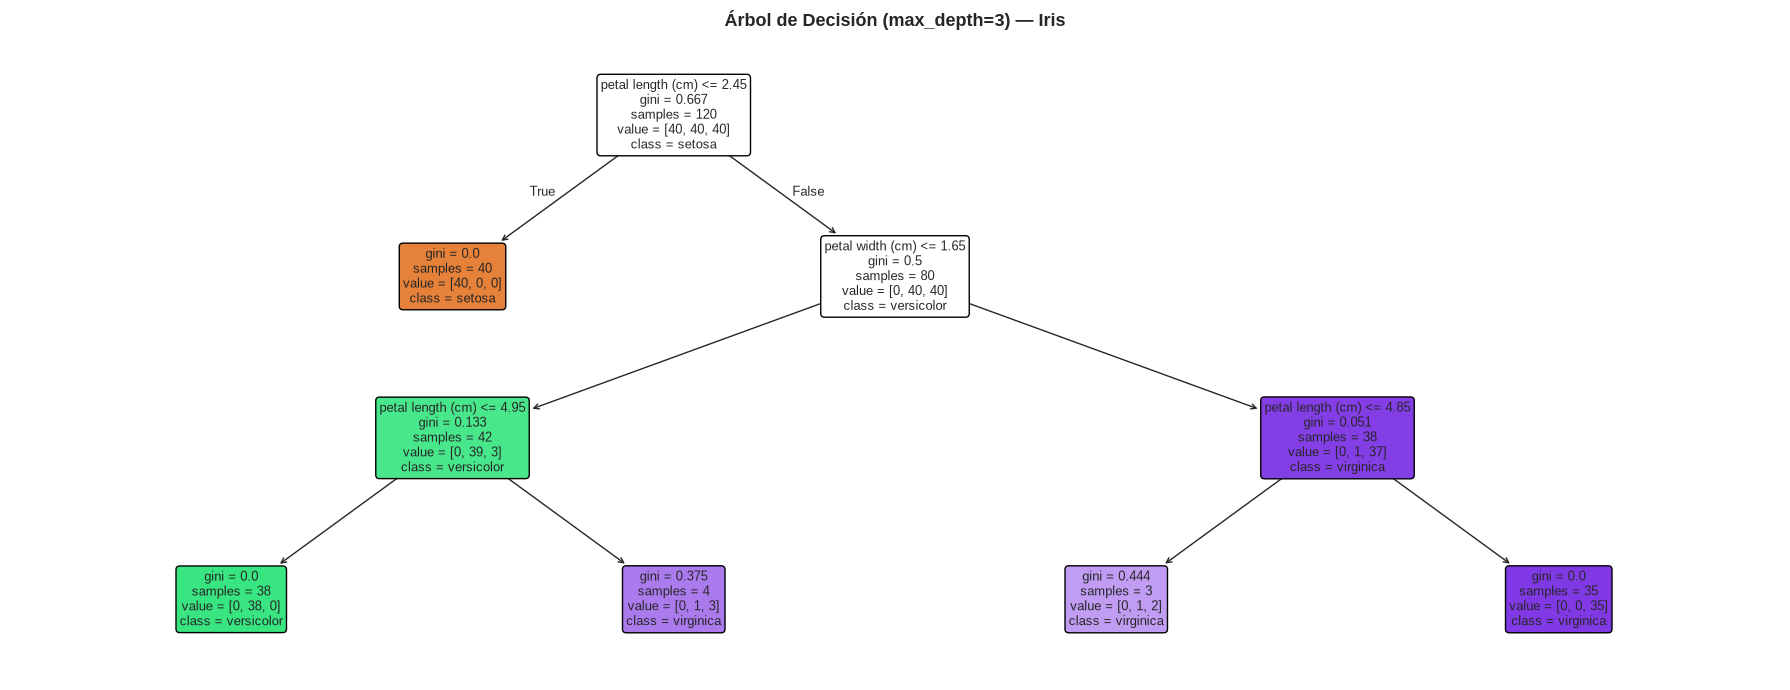

In [4]:
# =============================================================================
# VISUALIZACIÓN 1: El árbol completo (Iris — profundidad limitada a 3 para legibilidad)
# =============================================================================
dt_vis = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=SEED)
dt_vis.fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(
    dt_vis,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True, rounded=True,
    impurity=True,           # Mostrar Gini en cada nodo
    proportion=False,        # Mostrar conteos absolutos
    ax=ax, fontsize=9
)
ax.set_title('Árbol de Decisión (max_depth=3) — Iris', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [5]:
# =============================================================================
# EXPORTAR REGLAS EN TEXTO — máxima interpretabilidad
# =============================================================================
rules = export_text(dt_vis, feature_names=list(iris.feature_names))
print(rules)

|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.65
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- class: 2
|   |--- petal width (cm) >  1.65
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- class: 2
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- class: 2



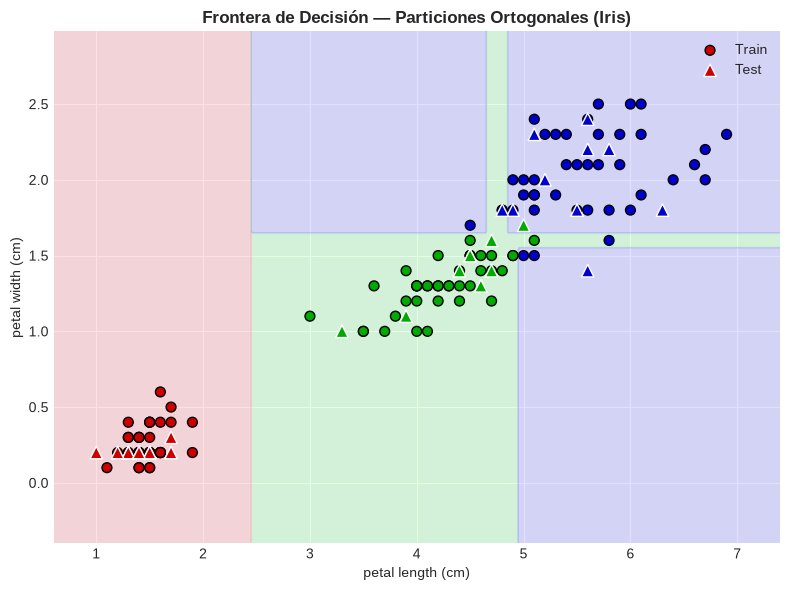

In [6]:
# =============================================================================
# FRONTERA DE DECISIÓN 2D (usando las 2 features más importantes)
# Ilustra visualmente las particiones ortogonales características de los DT
# =============================================================================
from matplotlib.colors import ListedColormap

feat_idx = np.argsort(dt_vis.feature_importances_)[::-1][:2]
feat_names_2 = [iris.feature_names[i] for i in feat_idx]

X_train_2d = X_train.iloc[:, feat_idx].values
X_test_2d  = X_test.iloc[:, feat_idx].values

dt_2d = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=SEED)
dt_2d.fit(X_train_2d, y_train)

h = 0.02
x0_min, x0_max = X_train_2d[:,0].min()-0.5, X_train_2d[:,0].max()+0.5
x1_min, x1_max = X_train_2d[:,1].min()-0.5, X_train_2d[:,1].max()+0.5
xx, yy = np.meshgrid(np.arange(x0_min, x0_max, h), np.arange(x1_min, x1_max, h))
Z = dt_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

cmap_bg  = ListedColormap(['#FFAAAA','#AAFFAA','#AAAAFF'])
cmap_pts = ListedColormap(['#CC0000','#00AA00','#0000CC'])

fig, ax = plt.subplots(figsize=(8, 6))
ax.contourf(xx, yy, Z, alpha=0.35, cmap=cmap_bg)
ax.scatter(X_train_2d[:,0], X_train_2d[:,1], c=y_train, cmap=cmap_pts,
           edgecolors='k', s=50, label='Train')
ax.scatter(X_test_2d[:,0], X_test_2d[:,1], c=y_test, cmap=cmap_pts,
           edgecolors='white', s=80, marker='^', label='Test')
ax.set_xlabel(feat_names_2[0]); ax.set_ylabel(feat_names_2[1])
ax.set_title('Frontera de Decisión — Particiones Ortogonales (Iris)', fontsize=12, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

---
## 8. Sobreajuste y Poda — Breast Cancer

Mejor max_depth: 3 | Test Accuracy: 0.9386


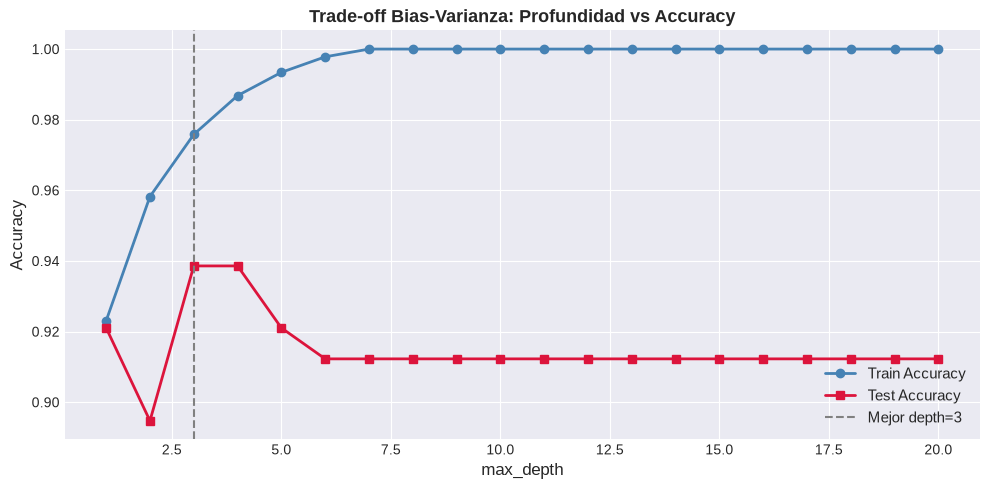

In [7]:
# =============================================================================
# CURVA DE COMPLEJIDAD: Train vs Test Accuracy vs max_depth
# Muestra el trade-off bias-varianza característico de los árboles
# =============================================================================
bc = load_breast_cancer(as_frame=True)
X_bc, y_bc = bc.data, bc.target

X_tr, X_te, y_tr, y_te = train_test_split(
    X_bc, y_bc, test_size=0.2, random_state=SEED, stratify=y_bc
)

depths = range(1, 21)
train_scores, test_scores = [], []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    dt.fit(X_tr, y_tr)
    train_scores.append(accuracy_score(y_tr, dt.predict(X_tr)))
    test_scores.append(accuracy_score(y_te, dt.predict(X_te)))

best_depth = list(depths)[np.argmax(test_scores)]
print(f'Mejor max_depth: {best_depth} | Test Accuracy: {max(test_scores):.4f}')

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(list(depths), train_scores, 'o-', color='steelblue', lw=2, label='Train Accuracy')
ax.plot(list(depths), test_scores,  's-', color='crimson',   lw=2, label='Test Accuracy')
ax.axvline(best_depth, color='gray', linestyle='--', label=f'Mejor depth={best_depth}')
ax.set_xlabel('max_depth', fontsize=12)
ax.set_ylabel('Accuracy', fontsize=12)
ax.set_title('Trade-off Bias-Varianza: Profundidad vs Accuracy', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

Mejor ccp_alpha: 0.005934


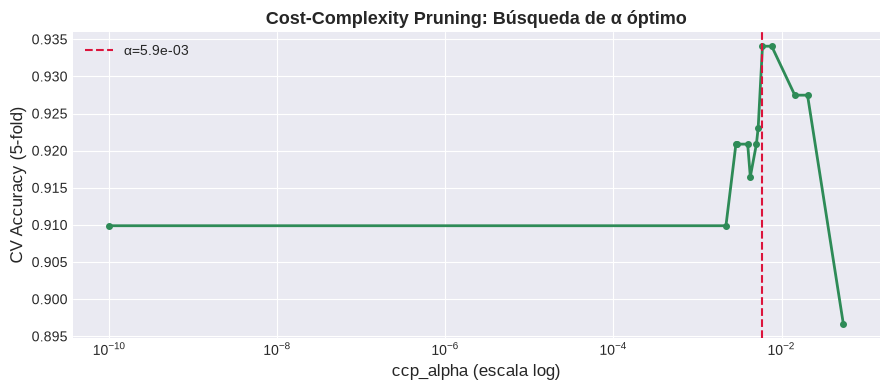

In [8]:
# =============================================================================
# COST-COMPLEXITY PRUNING (postpruning con ccp_alpha)
# scikit-learn genera la trayectoria de alphas óptimos automáticamente
# =============================================================================
# Calcular la trayectoria de poda
path = DecisionTreeClassifier(random_state=SEED).cost_complexity_pruning_path(X_tr, y_tr)
ccp_alphas = path.ccp_alphas[:-1]  # Excluir el último (árbol trivial de 1 nodo)

cv_scores_ccp = []
for alpha in ccp_alphas:
    dt_ccp = DecisionTreeClassifier(ccp_alpha=alpha, random_state=SEED)
    sc = cross_val_score(dt_ccp, X_tr, y_tr, cv=5, scoring='accuracy')
    cv_scores_ccp.append(sc.mean())

best_alpha = ccp_alphas[int(np.argmax(cv_scores_ccp))]
print(f'Mejor ccp_alpha: {best_alpha:.6f}')

fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogx(ccp_alphas + 1e-10, cv_scores_ccp, 'o-', color='seagreen', lw=2, ms=4)
ax.axvline(best_alpha + 1e-10, color='crimson', linestyle='--',
           label=f'α={best_alpha:.1e}')
ax.set_xlabel('ccp_alpha (escala log)', fontsize=12)
ax.set_ylabel('CV Accuracy (5-fold)', fontsize=12)
ax.set_title('Cost-Complexity Pruning: Búsqueda de α óptimo', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

In [9]:
# =============================================================================
# MODELO FINAL PODADO + EVALUACIÓN
# =============================================================================
dt_final = DecisionTreeClassifier(ccp_alpha=best_alpha, random_state=SEED)
dt_final.fit(X_tr, y_tr)
y_pred_final  = dt_final.predict(X_te)
y_proba_final = dt_final.predict_proba(X_te)[:, 1]

print(f'Árbol podado:')
print(f'  Profundidad : {dt_final.get_depth()}')
print(f'  Hojas       : {dt_final.get_n_leaves()}')
print(f'  Accuracy    : {accuracy_score(y_te, y_pred_final):.4f}')
print(f'  ROC-AUC     : {roc_auc_score(y_te, y_proba_final):.4f}')
print()
print(classification_report(y_te, y_pred_final, target_names=bc.target_names))

Árbol podado:
  Profundidad : 3
  Hojas       : 6
  Accuracy    : 0.9386
  ROC-AUC     : 0.9446

              precision    recall  f1-score   support

   malignant       0.93      0.90      0.92        42
      benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



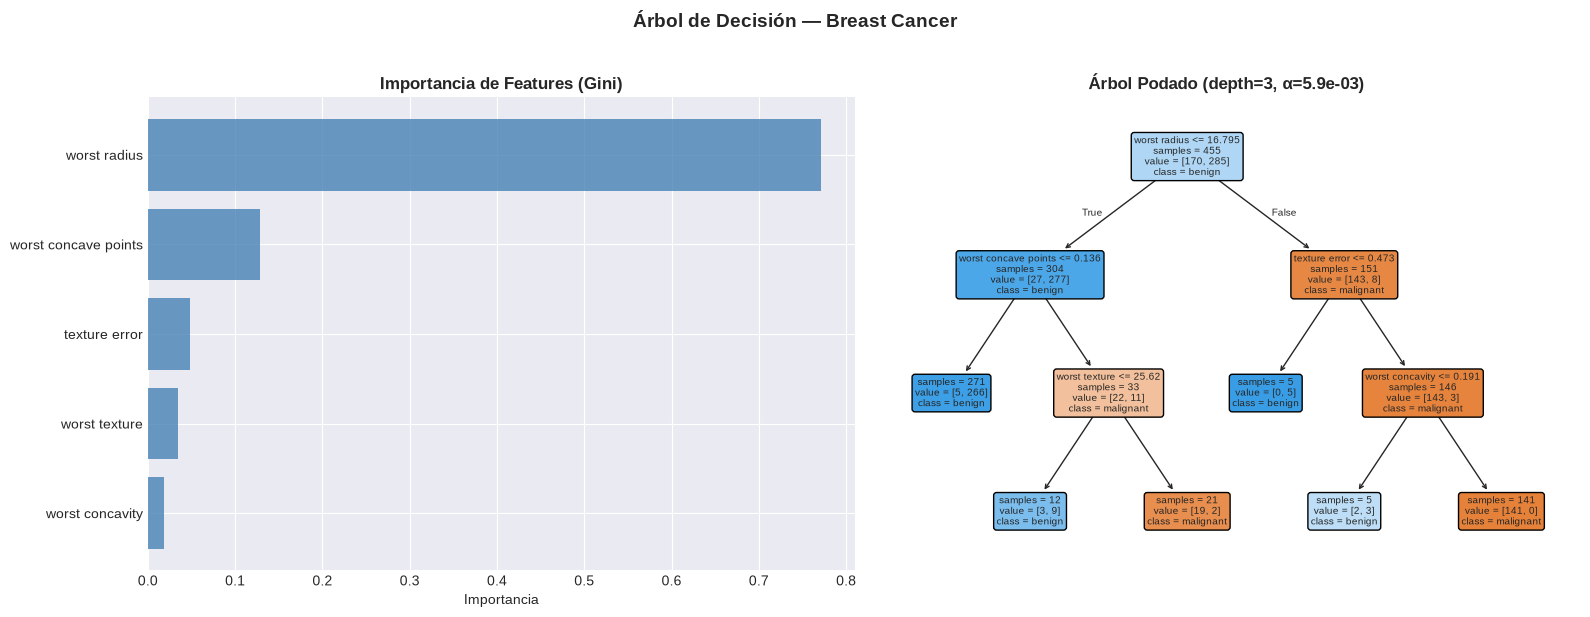

In [10]:
# =============================================================================
# VISUALIZACIÓN FINAL: Importancia de Features + Árbol podado
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Importancia de features
imp = pd.Series(dt_final.feature_importances_, index=bc.feature_names)
imp = imp[imp > 0].sort_values()
axes[0].barh(imp.index, imp.values, color='steelblue', alpha=0.8)
axes[0].set_title('Importancia de Features (Gini)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Importancia')

# Árbol podado
plot_tree(dt_final, feature_names=bc.feature_names, class_names=bc.target_names,
          filled=True, rounded=True, impurity=False, ax=axes[1], fontsize=7)
axes[1].set_title(f'Árbol Podado (depth={dt_final.get_depth()}, α={best_alpha:.1e})',
                  fontsize=12, fontweight='bold')

plt.suptitle('Árbol de Decisión — Breast Cancer', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 9. Resumen del Clasificador

| Aspecto | Detalle |
|---|---|
| **Interpretabilidad** | Máxima (reglas legibles) |
| **Preprocesamiento** | No requiere escalado |
| **Problema central** | Sobreajuste si no se controla la profundidad |
| **Regularización** | `max_depth`, `min_samples_leaf`, `ccp_alpha` |
| **Hiperparámetro clave** | `max_depth` o `ccp_alpha` |

### ✅ Checklist:
- [ ] ¿Grafiqué la curva Train vs Test para elegir `max_depth`?
- [ ] ¿Probé `ccp_alpha` como alternativa a la parada temprana?
- [ ] ¿Usé `class_weight='balanced'` si las clases están desbalanceadas?
- [ ] ¿Exporté las reglas con `export_text` para verificarlas?

---
*Ver notebook de regresión: `dt_regressor.ipynb`*